# Decision Trees Exercises

![DecisionTree.png](Assets/DecisionTree.png)


# Obiectivele cursului

- Recunoașteți arborii de decizie și modul în care aceștia pot fi utilizați pentru probleme de clasificare
- Aflați cum se determină cea mai bună divizare și factorii de divizare
- Explicați punctele forte și punctele slabe ale arborilor de decizie
- Explicați modul în care arborii de regresie ajută la clasificarea valorilor continue





## Introducere

Pentru aceste exerciții vom folosi un set de date privind calitatea vinului. Acest set de date conține diverse proprietăți chimice ale vinului, precum aciditatea, conținutul de zahăr, pH-ul și conținutul de alcool. De asemenea, conține un indicator al calității (3-9, unde valoarea cea mai mare indică o calitate mai bună) și culoarea (roșu sau alb). Numele fișierului este „Wine_Quality_Data.csv”.

In [12]:
%pip install pydotplus
from __future__ import print_function
import os
from pathlib import Path

from io import StringIO
from IPython.display import Image, display

from sklearn.tree import export_graphviz
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import mean_squared_error
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.tree import DecisionTreeClassifier
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

  Using cached pydotplus-2.0.2-py3-none-any.whl
Note: you may need to restart the kernel to use updated packages.


## Întrebarea 1

* Importați datele și studiați funcțiile.
* Le vom folosi pe toate pentru a prezice `color` (alb sau roșu), dar funcția culorilor trebuie codificată ca număr întreg.

Convertiți funcția de culoare într-un număr întreg. Iată o metodă rapidă de a face acest lucru folosind Pandas.

In [4]:
wine = pd.read_csv("Wine_Quality_Data.csv")

print("Dimensiunea setului de date:", wine.shape)
print("\nPrimele înregistrări:")
display(wine.head())
print("\nInformații despre coloane:")
wine.info()
print("\nStatistici descriptive:")
display(wine.describe(include="all"))

# Codificăm variabila țintă color ca întreg: red = 0, white = 1.
wine["color"] = wine["color"].map({"red": 0, "white": 1}).astype(int)

print("\nDistribuția valorilor pentru color după codificare:")
print(wine["color"].value_counts().sort_index())
print("Mapare: red = 0, white = 1")

Dimensiunea setului de date: (6497, 13)

Primele înregistrări:


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red



Informații despre coloane:
<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         6497 non-null   float64
 1   volatile_acidity      6497 non-null   float64
 2   citric_acid           6497 non-null   float64
 3   residual_sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free_sulfur_dioxide   6497 non-null   float64
 6   total_sulfur_dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  color                 6497 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 688.6 KB

Statistici descriptive:


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,white
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4898
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,5.818378,NaN
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.873255,NaN
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000,NaN
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000,NaN
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000,NaN
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000,NaN



Distribuția valorilor pentru color după codificare:
color
0    1599
1    4898
Name: count, dtype: int64
Mapare: red = 0, white = 1


## Întrebarea 2

* Utilizați `StratifiedShuffleSplit` pentru a împărți datele în seturi de trenuri și de teste, stratificate în funcție de calitatea vinului. Dacă este posibil, păstrați indicii privind ponderea pentru întrebarea 5 de mai jos.
* Verificați compoziția procentuală a fiecărui nivel de calitate pentru seturile de date privind trenurile și datele de testare.

In [5]:
X = wine.drop(columns=["color"])
y = wine["color"]

splitter = StratifiedShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(splitter.split(X, wine["quality"]))

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()
y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

print("Număr observații train:", len(train_idx))
print("Număr observații test:", len(test_idx))

quality_distribution = pd.DataFrame({
    "Întregul set (%)": wine["quality"].value_counts(normalize=True).sort_index() * 100,
    "Train (%)": wine.iloc[train_idx]["quality"].value_counts(normalize=True).sort_index() * 100,
    "Test (%)": wine.iloc[test_idx]["quality"].value_counts(normalize=True).sort_index() * 100
}).fillna(0)

display(quality_distribution.round(2))

Număr observații train: 5197
Număr observații test: 1300


,Întregul set (%),Train (%),Test (%)
quality,,,
3,0.46,0.46,0.46
4,3.32,3.33,3.31
5,32.91,32.90,32.92
6,43.65,43.66,43.62
7,16.61,16.61,16.62
8,2.97,2.96,3.00
9,0.08,0.08,0.08


## Întrebarea 3

* Construiți un clasificator pe baza unui arbore de decizie, fără restricții privind adâncimea maximă, numărul de caracteristici sau numărul de frunze.
* Determinați câte noduri sunt prezente în acest arbore (foarte mare) și care este adâncimea acestuia.
* Folosind acest arbore, evaluați eroarea de predicție pe seturile de date de antrenare și de testare. Ce credeți că se întâmplă aici, pe baza diferențelor dintre erorile de predicție?

In [6]:
tree_unrestricted = DecisionTreeClassifier(random_state=42)
tree_unrestricted.fit(X_train, y_train)

train_error_unrestricted = 1 - accuracy_score(y_train, tree_unrestricted.predict(X_train))
test_error_unrestricted = 1 - accuracy_score(y_test, tree_unrestricted.predict(X_test))

print("Număr de noduri:", tree_unrestricted.tree_.node_count)
print("Adâncime:", tree_unrestricted.get_depth())
print("Eroare de clasificare train:", round(train_error_unrestricted, 6))
print("Eroare de clasificare test:", round(test_error_unrestricted, 6))

Număr de noduri: 151
Adâncime: 21
Eroare de clasificare train: 0.000385
Eroare de clasificare test: 0.016923


## Întrebarea 4

* Folosind metoda de căutare în rețea cu validare încrucișată, găsiți un arbore de decizie care să dea rezultate bune pe setul de date de testare. Atribuiți acestui model de arbore de decizie un alt nume de variabilă decât cel din întrebarea 3, astfel încât ambele modele să poată fi utilizate la întrebarea 6.
* Determinați numărul de noduri și adâncimea acestui arbore.
* Calculați erorile pe seturile de date de antrenament și de testare, la fel ca mai devreme, și comparați-le cu erorile arborelui din întrebarea 3.

In [7]:
param_grid_classifier = {
    "max_depth": [3, 5, 7, 10, None],
    "max_features": [None, "sqrt", "log2"],
    "min_samples_leaf": [1, 2, 5]
}

classifier_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid_classifier,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)
classifier_grid.fit(X_train, y_train)

tree_optimized = classifier_grid.best_estimator_

train_error_optimized = 1 - accuracy_score(y_train, tree_optimized.predict(X_train))
test_error_optimized = 1 - accuracy_score(y_test, tree_optimized.predict(X_test))

print("Cei mai buni parametri:", classifier_grid.best_params_)
print("Acuratețe medie în validarea încrucișată:", round(classifier_grid.best_score_, 6))
print("Număr de noduri:", tree_optimized.tree_.node_count)
print("Adâncime:", tree_optimized.get_depth())
print("Eroare de clasificare train:", round(train_error_optimized, 6))
print("Eroare de clasificare test:", round(test_error_optimized, 6))

print("\nComparație erori:")
display(pd.DataFrame({
    "Model": ["Arbore fără restricții", "Arbore optimizat"],
    "Eroare train": [train_error_unrestricted, train_error_optimized],
    "Eroare test": [test_error_unrestricted, test_error_optimized]
}).set_index("Model").round(6))

Cei mai buni parametri: {'max_depth': 7, 'max_features': None, 'min_samples_leaf': 1}
Acuratețe medie în validarea încrucișată: 0.988455
Număr de noduri: 67
Adâncime: 7
Eroare de clasificare train: 0.00635
Eroare de clasificare test: 0.014615

Comparație erori:


,Eroare train,Eroare test
Model,,
Arbore fără restricții,0.000385,0.016923
Arbore optimizat,0.006350,0.014615


## Întrebarea 5

* Împărțiți din nou datele în părțile `X` și `y`, de data aceasta cu `residual_sugar` ca date de predicție (`y`). *Notă:* dacă indicii au fost salvați din rezultatele `StratifiedShuffleSplit` din întrebarea 2, aceștia pot fi reutilizați pentru împărțirea datelor.
* Folosind căutarea pe grilă cu validare încrucișată, găsiți un model de **regresie** bazat pe un arbore de decizie care să funcționeze bine pe setul de date de testare.
* Evaluați erorile pe seturile de date de antrenare și de testare folosind eroarea medie pătratică.
* Realizați un grafic care să prezinte atât valorile reale, cât și cele previzionate ale zahărului rezidual.

Cei mai buni parametri: {'max_depth': None, 'max_features': None, 'min_samples_leaf': 5}
MSE mediu în validarea încrucișată: 2.743422
Număr de noduri: 1663
Adâncime: 23
MSE train: 0.829903
MSE test: 3.051147


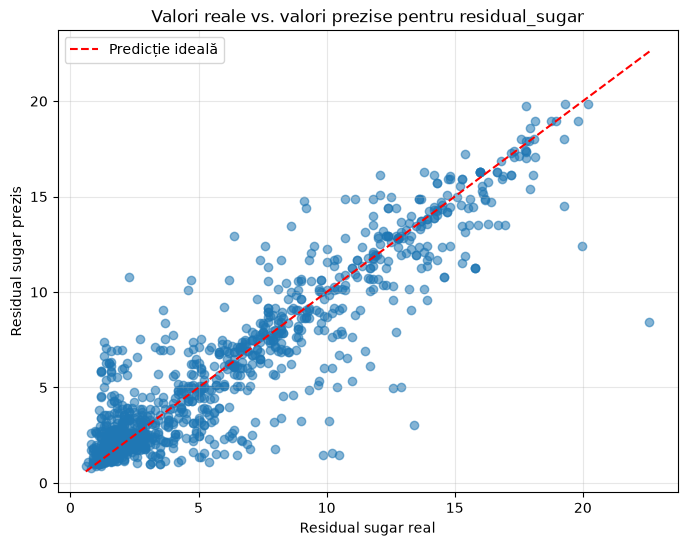

In [8]:
X_reg = wine.drop(columns=["residual_sugar"])
y_reg = wine["residual_sugar"]

X_reg_train = X_reg.iloc[train_idx].copy()
X_reg_test = X_reg.iloc[test_idx].copy()
y_reg_train = y_reg.iloc[train_idx].copy()
y_reg_test = y_reg.iloc[test_idx].copy()

param_grid_regressor = {
    "max_depth": [3, 5, 7, 10, None],
    "max_features": [None, "sqrt", "log2"],
    "min_samples_leaf": [1, 2, 5]
}

regressor_grid = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_grid=param_grid_regressor,
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)
regressor_grid.fit(X_reg_train, y_reg_train)

tree_regressor = regressor_grid.best_estimator_
pred_train_reg = tree_regressor.predict(X_reg_train)
pred_test_reg = tree_regressor.predict(X_reg_test)

mse_train = mean_squared_error(y_reg_train, pred_train_reg)
mse_test = mean_squared_error(y_reg_test, pred_test_reg)

print("Cei mai buni parametri:", regressor_grid.best_params_)
print("MSE mediu în validarea încrucișată:", round(-regressor_grid.best_score_, 6))
print("Număr de noduri:", tree_regressor.tree_.node_count)
print("Adâncime:", tree_regressor.get_depth())
print("MSE train:", round(mse_train, 6))
print("MSE test:", round(mse_test, 6))

# Grafic: valorile reale comparate cu valorile prezise pentru setul de testare.
plt.figure(figsize=(8, 6))
plt.scatter(y_reg_test, pred_test_reg, alpha=0.55)
min_value = min(y_reg_test.min(), pred_test_reg.min())
max_value = max(y_reg_test.max(), pred_test_reg.max())
plt.plot([min_value, max_value], [min_value, max_value], "r--", label="Predicție ideală")
plt.xlabel("Residual sugar real")
plt.ylabel("Residual sugar prezis")
plt.title("Valori reale vs. valori prezise pentru residual_sugar")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Întrebarea 6 *(Opțională)*

Această întrebare este opțională, deoarece pentru rezolvarea ei este necesar un program suplimentar de linie de comandă (GraphViz) și o bibliotecă Python (PyDotPlus). GraphViz poate fi instalat cu ajutorul managerului de pachete pe Linux și Mac. Pentru instalarea bibliotecii PyDotPlus se poate folosi fie `pip`, fie `conda` (`conda install -c conda-forge pydotplus`).

După instalarea acestor programe:

* Creați o vizualizare a arborelui de decizii din întrebarea 3, în care s-a prezis culoarea vinului, iar numărul de caracteristici și/sau diviziuni nu este limitat.
* Creați o vizualizare a arborelui de decizie din întrebarea 4, în care s-a prezis culoarea vinului, dar pentru a găsi adâncimea optimă și numărul optim de caracteristici s-a utilizat căutarea pe grilă.

Arborele de decizie din întrebarea 5 va avea, cel mai probabil, prea multe noduri pentru a putea fi vizualizat.

In [13]:
try:
    import pydotplus
    pydotplus_installed = True
    
except:
    print('PyDotPlus must be installed to execute the remainder of the cells associated with this question.')
    print('Please see the instructions for this question for details.')
    pydotplus_installed = False

if pydotplus_installed:
    try:
        dot_unrestricted = export_graphviz(
            tree_unrestricted,
            out_file=None,
            feature_names=X_train.columns,
            class_names=["red", "white"],
            filled=True,
            rounded=True,
            special_characters=True
        )
        graph_unrestricted = pydotplus.graph_from_dot_data(dot_unrestricted)
        display(Image(graph_unrestricted.create_png()))

        dot_optimized = export_graphviz(
            tree_optimized,
            out_file=None,
            feature_names=X_train.columns,
            class_names=["red", "white"],
            filled=True,
            rounded=True,
            special_characters=True
        )
        graph_optimized = pydotplus.graph_from_dot_data(dot_optimized)
        display(Image(graph_optimized.create_png()))
    except Exception as error:
        print("Nu s-a putut genera vizualizarea. Verificați instalarea GraphViz (executabilul dot).")
        print("Detalii:", error)
else:
    print("Întrebarea 6 este opțională. Instalați PyDotPlus și GraphViz pentru a genera arborii.")

Nu s-a putut genera vizualizarea. Verificați instalarea GraphViz (executabilul dot).
Detalii: GraphViz's executables not found
